# Airbnb: clean, split, train, cross-validate, test

**A 20-minute classroom demo.** We will predict whether a Sydney Airbnb listing costs **at least $300 per night**. This is a binary classification task, not a prediction of the exact price.

- **Training (60%):** practice questions; learn cleaning rules and model patterns.
- **Validation (20%):** a mock exam; choose between two simple models.
- **Cross-validation inside training:** rotate five practice groups to see how scores vary across splits.
- **Test (20%):** the final exam; evaluate the chosen model once.

**Stratification** keeps approximately the same proportion of each price class in all three sets. **Data leakage** means letting information from the exam influence learning. We will avoid it with a pipeline.

Data: Inside Airbnb, Sydney snapshot 16 June 2026, CC BY 4.0; supplied in `data/sydney_airbnb.csv`. Use the same Python environment as the other course notebooks, then **Run All**. No downloads are needed.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, balanced_accuracy_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
PRICE_THRESHOLD = 300

## 1. Load a small selection of columns

Each row is a listing. We use only five easy-to-explain inputs. `price` creates the answer; `id` identifies duplicate listings. **Neither will be an input to the model.** Revenue is also excluded because it may be calculated using price.

In [2]:
data_path = Path('data') / 'sydney_airbnb.csv'
if not data_path.is_file():
    data_path = (Path('IATD-Machine-Learning-Algorithms')
                 / 'IATD-Machine-Learning-Algorithms' / 'data' / 'sydney_airbnb.csv')
if not data_path.is_file():
    raise FileNotFoundError('Open this notebook from the course folder or MachineLearning workspace.')

numeric_columns = ['accommodates', 'bedrooms', 'bathrooms']
categorical_columns = ['suburb', 'room_type']
feature_columns = numeric_columns + categorical_columns
raw = pd.read_csv(data_path, usecols=['id', 'price'] + feature_columns)
print(f'Loaded {len(raw):,} listings')
display(raw.head())
display(raw.isna().sum().rename('Missing values before cleaning').to_frame())

Loaded 20,573 listings


,id,suburb,room_type,accommodates,bathrooms,bedrooms,price
0,11156,Sydney,Private room,1,NaN,NaN,24.7
1,15253,Sydney,Private room,2,1.0,NaN,144.7
2,44545,Sydney,Entire home/apt,2,NaN,1.0,NaN
3,58506,Mosman,Entire home/apt,4,1.0,1.0,240.0
4,1141803,Sydney,Entire home/apt,2,1.0,1.0,456.5


,Missing values before cleaning
id,0
suburb,0
room_type,0
accommodates,0
bathrooms,5724
bedrooms,3107
price,2787


## 2. Clean fixed data-quality problems

We remove repeated listing IDs, standardise whitespace, and turn invalid numbers into missing values. Zero bedrooms can mean a studio, so it is allowed. A listing must have a known, positive price to provide a trustworthy answer.

**Do not fill missing inputs yet.** Fixed rules can be applied before splitting because they do not learn averages or patterns. Median values and category encodings must be learned from training data only. The report shows actual changes; some counts may be zero.

In [3]:
df = raw.drop_duplicates(subset='id').copy()
duplicates_removed = len(raw) - len(df)

for column in ['price'] + numeric_columns:
    df[column] = pd.to_numeric(df[column], errors='coerce')
df[['price'] + numeric_columns] = df[['price'] + numeric_columns].replace([np.inf, -np.inf], np.nan)

invalid_features = pd.DataFrame({
    'accommodates': df['accommodates'] <= 0,
    'bedrooms': df['bedrooms'] < 0,
    'bathrooms': df['bathrooms'] <= 0,
})
df[numeric_columns] = df[numeric_columns].mask(invalid_features)
for column in categorical_columns:
    df[column] = df[column].str.strip().replace('', np.nan)

missing_or_invalid_price = df['price'].isna() | (df['price'] <= 0)
unlabelled_removed = int(missing_or_invalid_price.sum())
df = df.loc[~missing_or_invalid_price].copy()
df['high_price'] = (df['price'] >= PRICE_THRESHOLD).astype(int)

display(pd.Series({
    'Duplicate listing rows removed': duplicates_removed,
    'Missing/nonpositive price rows removed': unlabelled_removed,
    'Invalid input values marked missing': int(invalid_features.sum().sum()),
    'Labelled rows remaining': len(df),
}).to_frame('Count'))
display(df[feature_columns].isna().sum().to_frame('Missing inputs still to fill'))
display(df['high_price'].value_counts().sort_index().rename_axis('Class').to_frame('Listings'))
print('Class 0: price < $300; class 1: price >= $300. Threshold fixed for teaching, not learned from the data.')

,Count
Duplicate listing rows removed,0
Missing/nonpositive price rows removed,2787
Invalid input values marked missing,0
Labelled rows remaining,17786


,Missing inputs still to fill
accommodates,0
bedrooms,2727
bathrooms,3022
suburb,0
room_type,0


,Listings
Class,
0,9207
1,8579


Class 0: price < $300; class 1: price >= $300. Threshold fixed for teaching, not learned from the data.


## 3. Make a stratified 60 / 20 / 20 split

First keep **60% for training** and hold out 40%. Then split the held-out portion in half: **20% validation + 20% test** of the original labelled data.

`stratify=y` preserves class proportions; it does not balance them to 50/50. The second split must stratify using **the held-out labels**, not the full labels. `random_state` makes the example reproducible.

It is normal to use labels for stratification. Do not use test predictions or scores to choose a model.

,Rows,Share of data (%),Class 0 (%),Class 1 (%)
Set,,,,
All labelled data,17786,100.0,51.77,48.23
Training,10671,60.0,51.77,48.23
Validation,3557,20.0,51.76,48.24
Test,3558,20.0,51.77,48.23


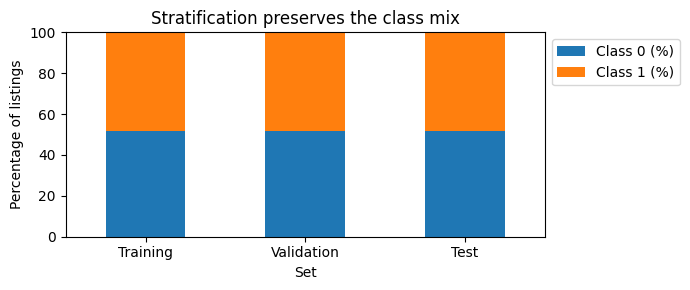

In [4]:
X = df[feature_columns]
y = df['high_price']

X_train, X_holdout, y_train, y_holdout = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED
)
X_val, X_test, y_val, y_test = train_test_split(
    X_holdout, y_holdout, test_size=0.50, stratify=y_holdout, random_state=SEED
)

assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert set(X_train.index) | set(X_val.index) | set(X_test.index) == set(X.index)

split_summary = pd.DataFrame([
    {'Set': name, 'Rows': len(labels), 'Share of data (%)': 100 * len(labels) / len(y),
     'Class 0 (%)': 100 * (1 - labels.mean()), 'Class 1 (%)': 100 * labels.mean()}
    for name, labels in [('All labelled data', y), ('Training', y_train),
                         ('Validation', y_val), ('Test', y_test)]
]).set_index('Set')
display(split_summary.round(2))
for labels in [y_train, y_val, y_test]:
    assert abs(labels.mean() - y.mean()) < 0.002

split_summary.loc[['Training', 'Validation', 'Test'], ['Class 0 (%)', 'Class 1 (%)']].plot.bar(
    stacked=True, figsize=(7, 3), rot=0, ylim=(0, 100), ylabel='Percentage of listings',
    title='Stratification preserves the class mix'
)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

## 4. Put learned cleaning and the model in one pipeline

- **Numeric inputs:** fill missing values with the training median.
- **Categorical inputs:** fill gaps with the training most-frequent category, then one-hot encode (make category indicator columns).
- **Unknown categories:** `handle_unknown='ignore'` lets a new suburb be processed without an error.
- **Decision tree:** learn simple questions such as 'bedrooms > 2?'. `max_depth` limits how many levels of questions it can ask. Trees do not require scaling.

`fit(X_train, y_train)` learns both preprocessing and the tree. `predict(X_val)` reuses those rules; it does **not** recalculate medians on validation data.

In [5]:
def make_model(depth):
    preprocessing = ColumnTransformer([
        ('numbers', SimpleImputer(strategy='median'), numeric_columns),
        ('categories', Pipeline([
            ('fill', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore')),
        ]), categorical_columns),
    ])
    return Pipeline([
        ('clean', preprocessing),
        ('model', DecisionTreeClassifier(max_depth=depth, random_state=SEED)),
    ])

## 5. Train on training data; choose using validation data

Compare two depths, 3 and 5. A deeper tree can learn more detail, but can also memorise noise (**overfit**).

**Accuracy** is the fraction of correct answers. **Balanced accuracy** averages recall across the two classes, giving each class equal weight. We choose the higher validation balanced accuracy, keeping the shallower tree if tied.

A **baseline** always guesses the most common training class. A model should improve on this simple reference. Do not open the test results yet.

In [6]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_val = baseline.predict(X_val)
print(f'Baseline validation accuracy: {accuracy_score(y_val, baseline_val):.3f}')
print(f'Baseline validation balanced accuracy: {balanced_accuracy_score(y_val, baseline_val):.3f}')

models = {}
results = []
for depth in [3, 5]:
    model = make_model(depth)
    model.fit(X_train, y_train)
    models[depth] = model
    train_predictions = model.predict(X_train)
    val_predictions = model.predict(X_val)
    results.append({
        'Depth': depth,
        'Training accuracy': accuracy_score(y_train, train_predictions),
        'Validation accuracy': accuracy_score(y_val, val_predictions),
        'Validation balanced accuracy': balanced_accuracy_score(y_val, val_predictions),
    })

validation_results = pd.DataFrame(results).set_index('Depth')
display(validation_results.round(3))
best_depth = validation_results['Validation balanced accuracy'].idxmax()
best_model = models[best_depth]
print(f'Chosen depth: {best_depth}. The test set has not been used for model selection.')

Baseline validation accuracy: 0.518
Baseline validation balanced accuracy: 0.500


,Training accuracy,Validation accuracy,Validation balanced accuracy
Depth,,,
3,0.783,0.780,0.780
5,0.791,0.781,0.781


Chosen depth: 5. The test set has not been used for model selection.


### Check: where did the filling values come from?

The learned imputer values must equal the **training medians**. Missing inputs remain in the original tables; the pipeline fills them internally when transforming data. It also produces fully numeric inputs for the tree.

In [7]:
numeric_imputer = best_model.named_steps['clean'].named_transformers_['numbers']
learned_medians = pd.Series(numeric_imputer.statistics_, index=numeric_columns)
display(pd.DataFrame({
    'Training median': X_train[numeric_columns].median(),
    'Pipeline filling value': learned_medians,
}))
np.testing.assert_allclose(learned_medians, X_train[numeric_columns].median())
cleaned_validation = best_model.named_steps['clean'].transform(X_val)
cleaned_values = (cleaned_validation.data if hasattr(cleaned_validation, 'toarray')
                  else cleaned_validation)
assert np.isfinite(cleaned_values).all()
print('Verified: training-only medians, and no missing/infinite values reach the model.')

,Training median,Pipeline filling value
accommodates,4.0,4.0
bedrooms,2.0,2.0
bathrooms,1.0,1.0


Verified: training-only medians, and no missing/infinite values reach the model.


## 6. K-fold cross-validation: take turns being the mock exam

One validation score depends on which listings happened to land in that split. **K-fold cross-validation** repeats training and scoring on several different partitions. Here **K = 5**, so we divide **only the original training set** into five approximately equal groups called folds.

For each round, a fresh model learns from four folds and is scored on the remaining fold. Each listing is held out once and used for learning in the other four rounds. These are **internal validation folds**, not five final test sets.

| Round | Fold A | Fold B | Fold C | Fold D | Fold E |
|---|---|---|---|---|---|
| 1 | Validate | Learn | Learn | Learn | Learn |
| 2 | Learn | Validate | Learn | Learn | Learn |
| 3 | Learn | Learn | Validate | Learn | Learn |
| 4 | Learn | Learn | Learn | Validate | Learn |
| 5 | Learn | Learn | Learn | Learn | Validate |

We use **StratifiedKFold**, the classification version of K-fold: it preserves approximately the same class mix in each held-out fold. `shuffle=True` mixes rows before forming folds, and the seed makes the result repeatable.

**Keep the boundaries clear:** the original validation set and test set do not enter these folds. Each round learns from about 80% of the original 60% training allocation, or about **48% of all labelled rows**. Its internal validation fold is about **12% of all labelled rows**.

For this demo, we cross-validate the depth already chosen in step 5 to illustrate score variation; we do not use this extra check to change the chosen model. The CV average is not an independent final score for the whole selection process. In a typical alternative workflow, CV replaces the separate validation set when comparing depths, while a final test set still stays untouched.

In [8]:
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(kfold.split(X_train, y_train))

fold_summary = pd.DataFrame([
    {'Round': number, 'Rows to learn from': len(learn_rows),
     'Rows to validate on': len(check_rows),
     'High-price class in learning (%)': 100 * y_train.iloc[learn_rows].mean(),
     'High-price class in validation (%)': 100 * y_train.iloc[check_rows].mean()}
    for number, (learn_rows, check_rows) in enumerate(folds, start=1)
]).set_index('Round')
display(fold_summary.round(2))

for learn_rows, check_rows in folds:
    assert set(learn_rows).isdisjoint(check_rows)
    assert len(learn_rows) + len(check_rows) == len(X_train)
    assert abs(y_train.iloc[check_rows].mean() - y_train.mean()) < 0.002
held_out_rows = np.concatenate([check_rows for _, check_rows in folds])
assert np.array_equal(np.sort(held_out_rows), np.arange(len(X_train)))
print('Verified: each training listing is held out exactly once; fold class proportions are preserved.')

,Rows to learn from,Rows to validate on,High-price class in learning (%),High-price class in validation (%)
Round,,,,
1,8536,2135,48.23,48.24
2,8537,2134,48.24,48.22
3,8537,2134,48.24,48.22
4,8537,2134,48.24,48.22
5,8537,2134,48.23,48.27


Verified: each training listing is held out exactly once; fold class proportions are preserved.


### Run the five rounds and read the scores

`cross_val_score` creates a fresh copy of the **entire pipeline** for each round. That means medians, category filling values, encodings and the tree are learned only from that round's four learning folds. Passing a table that had already been imputed using all training rows would leak information into the held-out fold.

We use the same **balanced accuracy** metric as before. The **mean** summarises the five scores. The **standard deviation** describes their spread: a smaller value means scores were more similar for these folds, not that the model is guaranteed to work on future data. It is not a confidence interval.

`error_score='raise'` makes a failed fold report an error rather than hiding a training problem. Cross-validation takes more work because it fits five models. It does not modify our previously fitted `best_model` or choose one winning fold.

In [9]:
cv_scores = cross_val_score(
    make_model(best_depth), X_train, y_train,
    cv=folds, scoring='balanced_accuracy', error_score='raise'
)
assert len(cv_scores) == 5 and np.isfinite(cv_scores).all()
display(pd.DataFrame({
    'Round': range(1, 6), 'Held-out fold balanced accuracy': cv_scores,
}).set_index('Round').round(3))
print(f'Mean CV balanced accuracy: {cv_scores.mean():.3f}')
print(f'Standard deviation across folds: {cv_scores.std(ddof=1):.3f}')
print('Five fresh pipelines were fitted. The original validation and test rows stayed outside CV.')

,Held-out fold balanced accuracy
Round,
1,0.801
2,0.773
3,0.801
4,0.784
5,0.775


Mean CV balanced accuracy: 0.787
Standard deviation across folds: 0.013
Five fresh pipelines were fitted. The original validation and test rows stayed outside CV.


## 7. Open the test set once

Evaluate only the model already selected on validation, alongside the fixed baseline. For simplicity, we keep the training-fitted winner rather than refitting on training + validation.

In the confusion matrix, rows are actual classes and columns are predicted classes. Diagonal entries are correct; off-diagonal entries are mistakes. **Do not change the depth or features in response to this test score.** That would turn the test set into another validation set.

,Test accuracy,Test balanced accuracy
Model,,
Majority baseline,0.518,0.500
Decision tree (depth 5),0.791,0.791


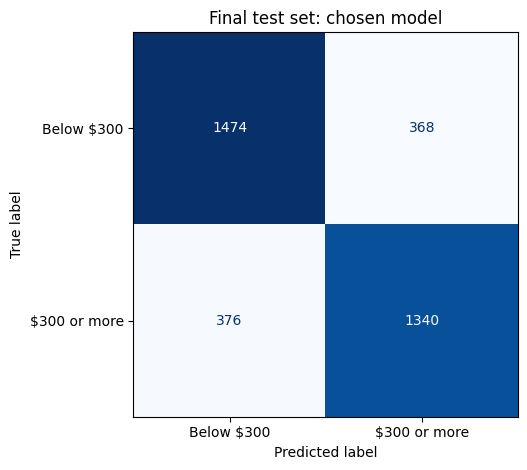

,accommodates,bedrooms,bathrooms,suburb,room_type,Actual high-price class,Predicted high-price class
13055,6,2.0,2.5,Blacktown,Entire home/apt,0,0
14578,8,3.0,2.0,Penrith,Entire home/apt,0,1
18675,2,1.0,1.0,Burwood,Private room,0,0
12909,2,NaN,1.0,Fairfield,Private room,0,0
4335,3,1.0,1.0,Sydney,Entire home/apt,1,1


In [10]:
test_predictions = best_model.predict(X_test)
baseline_test_predictions = baseline.predict(X_test)
display(pd.DataFrame([
    {'Model': name, 'Test accuracy': accuracy_score(y_test, predictions),
     'Test balanced accuracy': balanced_accuracy_score(y_test, predictions)}
    for name, predictions in [('Majority baseline', baseline_test_predictions),
                              (f'Decision tree (depth {best_depth})', test_predictions)]
]).set_index('Model').round(3))

ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, labels=[0, 1],
    display_labels=['Below $300', '$300 or more'], cmap='Blues', colorbar=False
)
plt.title('Final test set: chosen model')
plt.tight_layout()
plt.show()

examples = X_test.head().copy()
examples['Actual high-price class'] = y_test.head()
examples['Predicted high-price class'] = test_predictions[:len(examples)]
display(examples)

## Recap and questions for students

1. **Clean fixed errors**, but do not fill missing target prices with guesses.
2. **Split rows, not columns.** Stratification preserves the label mix; the three sets have no shared listings.
3. **Learn preprocessing on training only.** A pipeline carries those same rules into validation, test and future predictions.
4. **Train to learn; validate to choose; test to report.** A correlation plot alone cannot measure prediction performance.
5. **Cross-validation rotates internal validation folds.** Relearn the entire pipeline in every round; keep the final test set outside all folds.

**Discuss:** Why is the second `test_size` 0.50 rather than 0.20? Why must price not appear in `X`? Why is a large training score not enough? What does balanced accuracy reveal that ordinary accuracy can hide? In 5-fold CV, how often is each training listing held out? Why must we learn new medians in every fold? Does CV use our final test set?

**Limitations:** This random split evaluates other listings from the same snapshot, not future market prices. Different listings may share a host; a host-grouped split would be needed to evaluate unseen hosts. Stratification does not fix those dependencies or distribution changes. The $300 cutoff is a teaching choice, not a business recommendation; classification scores do not tell us the dollar error in a price estimate.

**Optional classroom experiment:** Before treating any score as final, rerun the lesson with `stratify` removed from both split calls and compare class percentages. With this large dataset, random splitting may already look similar; stratification guarantees a much closer mix. Do not use repeated test results to pick a preferred random seed or model.